In [14]:
!nvidia-smi

Tue Nov 24 05:22:48 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8             14W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [15]:
!wget -q https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip -O sms.zip
!unzip -o sms.zip -d Datasets

Archive:  sms.zip
  inflating: Datasets/SMSSpamCollection  
  inflating: Datasets/readme         


In [16]:
import nltk
nltk.download('wordnet')
from nltk.stem import WordNetLemmatizer
lemmatizer = WordNetLemmatizer()
print(lemmatizer.lemmatize("discovering"))

discovering


[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [17]:
from nltk.stem import PorterStemmer
ps = PorterStemmer()
print(ps.stem("discovering"))

discov


In [18]:
import pandas as pd

messages = pd.read_csv('Datasets/SMSSpamCollection', sep='\t',
                       names=["label", "message"])
messages.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [19]:
messages

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [20]:
messages['message'].loc[451]

'hanks lotsly!'

In [21]:
#Data cleaning and preprocessing
import re
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [22]:
from nltk.corpus import stopwords

In [23]:
corpus = []
for i in range(0, len(messages)):
    review = re.sub('[^a-zA-Z]', ' ', messages['message'][i])
    review = review.lower()
    review = review.split()

    review = [ps.stem(word) for word in review if not word in stopwords.words('english')]
    review = ' '.join(review)
    corpus.append(review)

In [24]:
corpus

['go jurong point crazi avail bugi n great world la e buffet cine got amor wat',
 'ok lar joke wif u oni',
 'free entri wkli comp win fa cup final tkt st may text fa receiv entri question std txt rate c appli',
 'u dun say earli hor u c alreadi say',
 'nah think goe usf live around though',
 'freemsg hey darl week word back like fun still tb ok xxx std chg send rcv',
 'even brother like speak treat like aid patent',
 'per request mell mell oru minnaminungint nurungu vettam set callertun caller press copi friend callertun',
 'winner valu network custom select receivea prize reward claim call claim code kl valid hour',
 'mobil month u r entitl updat latest colour mobil camera free call mobil updat co free',
 'gonna home soon want talk stuff anymor tonight k cri enough today',
 'six chanc win cash pound txt csh send cost p day day tsandc appli repli hl info',
 'urgent week free membership prize jackpot txt word claim c www dbuk net lccltd pobox ldnw rw',
 'search right word thank breather

In [25]:
# Creating the Bag of Words model
from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer(max_features=2500,binary=True)
X = cv.fit_transform(corpus).toarray()

In [26]:
messages['label']

,label
0,ham
1,ham
2,spam
3,ham
4,ham
...,...
5567,spam
5568,ham
5569,ham
5570,ham


In [27]:
y=pd.get_dummies(messages['label'])
y=y.iloc[:,1].values
y

array([False, False,  True, ..., False, False, False], shape=(5572,))

In [28]:
# Train Test Split

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 0)

In [29]:
from sklearn.naive_bayes import MultinomialNB
spam_detect_model = MultinomialNB().fit(X_train, y_train)

In [30]:
#prediction
y_pred=spam_detect_model.predict(X_test)
y_pred

array([False,  True, False, ..., False,  True, False], shape=(1115,))

In [31]:
from sklearn.metrics import accuracy_score,classification_report

In [32]:
score=accuracy_score(y_test,y_pred)
print(score)

0.9865470852017937


In [33]:
from sklearn.metrics import classification_report
print(classification_report(y_pred,y_test))

              precision    recall  f1-score   support

       False       0.99      0.99      0.99       960
        True       0.94      0.97      0.95       155

    accuracy                           0.99      1115
   macro avg       0.97      0.98      0.97      1115
weighted avg       0.99      0.99      0.99      1115



In [34]:
# Creating the TFIDF model
from sklearn.feature_extraction.text import TfidfVectorizer
tv = TfidfVectorizer(max_features=2500)
X = tv.fit_transform(corpus).toarray()

In [35]:
# Train Test Split

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 0)

In [36]:
from sklearn.naive_bayes import MultinomialNB
spam_detect_model = MultinomialNB().fit(X_train, y_train)

In [37]:
#prediction
y_pred=spam_detect_model.predict(X_test)
y_pred

array([False, False, False, ..., False,  True, False], shape=(1115,))

In [38]:
score=accuracy_score(y_test,y_pred)
print(score)

0.9811659192825112


In [39]:
from sklearn.metrics import classification_report
print(classification_report(y_pred,y_test))

              precision    recall  f1-score   support

       False       1.00      0.98      0.99       976
        True       0.87      1.00      0.93       139

    accuracy                           0.98      1115
   macro avg       0.93      0.99      0.96      1115
weighted avg       0.98      0.98      0.98      1115



Here you can use other algorithms like randomforest.

# Word2vec Implementation

In [40]:
!pip install --upgrade gensim

In [41]:
from nltk.stem import WordNetLemmatizer
lemmatizer=WordNetLemmatizer()

In [42]:
import nltk
nltk.download('wordnet')
nltk.download('stopwords')

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [43]:
# importing the Dataset

import pandas as pd
from nltk.corpus import stopwords
import re
messages = pd.read_csv('/content/drive/MyDrive/Machine Learning/Deep learning/deep_learning/dataset/spamsmstext/SMSSpamCollection.txt', sep='\t',
                           names=["label", "message"])

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Machine Learning/Deep learning/deep_learning/dataset/spamsmstext/SMSSpamCollection.txt'

In [ ]:
corpus = []
for i in range(0, len(messages)):
    review = re.sub('[^a-zA-Z]', ' ', messages['message'][i])
    review = review.lower()
    review = review.split()

    review = [lemmatizer.lemmatize(word) for word in review if not word in stopwords.words('english')]
    review = ' '.join(review)
    corpus.append(review)

In [ ]:
corpus

['go jurong point crazy available bugis n great world la e buffet cine got amore wat',
 'ok lar joking wif u oni',
 'free entry wkly comp win fa cup final tkts st may text fa receive entry question std txt rate c apply',
 'u dun say early hor u c already say',
 'nah think go usf life around though',
 'freemsg hey darling week word back like fun still tb ok xxx std chgs send rcv',
 'even brother like speak treat like aid patent',
 'per request melle melle oru minnaminunginte nurungu vettam set callertune caller press copy friend callertune',
 'winner valued network customer selected receivea prize reward claim call claim code kl valid hour',
 'mobile month u r entitled update latest colour mobile camera free call mobile update co free',
 'gonna home soon want talk stuff anymore tonight k cried enough today',
 'six chance win cash pound txt csh send cost p day day tsandcs apply reply hl info',
 'urgent week free membership prize jackpot txt word claim c www dbuk net lccltd pobox ldnw rw'

In [ ]:
from nltk import sent_tokenize
from gensim.utils import simple_preprocess

In [ ]:
corpus[0]

'go jurong point crazy available bugis n great world la e buffet cine got amore wat'

In [ ]:
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
words=[]
for sent in corpus:
    sent_token=sent_tokenize(sent)
    for sent in sent_token:
        words.append(simple_preprocess(sent))

In [ ]:
len(words)

5564

In [ ]:
import gensim

In [ ]:
### Lets train Word2vec from scratch
#by default vector size is 100
# window is how many context in the left and right
model=gensim.models.Word2Vec(words,window=5,min_count=1)

In [ ]:
model.wv.index_to_key

['call',
 'get',
 'ur',
 'gt',
 'lt',
 'go',
 'day',
 'ok',
 'free',
 'know',
 'come',
 'like',
 'good',
 'time',
 'got',
 'love',
 'text',
 'want',
 'send',
 'one',
 'need',
 'txt',
 'today',
 'going',
 'stop',
 'home',
 'lor',
 'sorry',
 'see',
 'still',
 'mobile',
 'take',
 'back',
 'da',
 'reply',
 'dont',
 'think',
 'tell',
 'week',
 'phone',
 'hi',
 'new',
 'later',
 'please',
 'pls',
 'co',
 'msg',
 'min',
 'dear',
 'night',
 'make',
 'message',
 'well',
 'say',
 'thing',
 'much',
 'hope',
 'oh',
 'claim',
 'great',
 'hey',
 'number',
 'give',
 'happy',
 'work',
 'friend',
 'wat',
 'way',
 'yes',
 'www',
 'let',
 'prize',
 'right',
 'tomorrow',
 'already',
 'tone',
 'said',
 'ask',
 'win',
 'amp',
 'cash',
 'life',
 'im',
 'yeah',
 'really',
 'babe',
 'meet',
 'find',
 'miss',
 'morning',
 'last',
 'service',
 'year',
 'uk',
 'thanks',
 'care',
 'would',
 'anything',
 'com',
 'also',
 'nokia',
 'lol',
 'every',
 'feel',
 'keep',
 'pick',
 'sure',
 'sent',
 'contact',
 'urgent',


In [ ]:
model.corpus_count

5564

In [ ]:
model.epochs

5

In [ ]:
model.wv.similar_by_word('coffee')

[('number', 0.9899853467941284),
 ('made', 0.989895761013031),
 ('hurt', 0.9895991086959839),
 ('latest', 0.9895274639129639),
 ('already', 0.9895207285881042),
 ('gud', 0.989495575428009),
 ('phone', 0.9894663691520691),
 ('co', 0.9894393086433411),
 ('miss', 0.9894106388092041),
 ('night', 0.9893369078636169)]

In [ ]:
model.wv['coffee'].shape

(100,)

In [ ]:
import numpy as np
# def avg_word2vec(doc):
#     # remove out-of-vocabulary words
#     sent = [word for word in doc if word in model.wv.index_to_key]

#     return np.mean([np.zeros(len(model.wv.index_to_key))], axis=0)

def avg_word2vec(doc):
    vectors = []
    for w in doc:
        if w in model.wv:
            vectors.append(model.wv[w])

    if len(vectors) == 0:
        return np.zeros(model.vector_size)

    return np.mean(vectors, axis=0)


In [ ]:
!pip install tqdm

In [ ]:
from tqdm import tqdm

In [ ]:
#apply for the entire sentences
print(len(words))
# for i in tqdm(range(len(words))):
#     #print(avg_word2vec(words[i]))
#     X.append(avg_word2vec(words[i]))


X = [avg_word2vec(sentence) for sentence in words]




5564


In [ ]:
X_new=np.array(X)

In [ ]:
X_new.shape

(5564, 100)

In [ ]:
X_new

array([[-0.12311652,  0.16338955,  0.00364421, ..., -0.192269  ,
         0.09240662,  0.00908584],
       [-0.07969198,  0.11420603,  0.0013243 , ..., -0.13622428,
         0.0665787 ,  0.00782344],
       [-0.12907097,  0.17322168,  0.00777092, ..., -0.19795887,
         0.0954448 ,  0.00991757],
       ...,
       [-0.01031259,  0.01371963, -0.00347861, ..., -0.02227469,
         0.0131657 , -0.00265431],
       [-0.1408554 ,  0.18483263,  0.00246366, ..., -0.21631055,
         0.1040198 ,  0.01349731],
       [-0.10325222,  0.13110183, -0.00462711, ..., -0.1550746 ,
         0.06859583,  0.0077087 ]])

In [ ]:
## Dependent Features
## Output Features
y = messages[list(map(lambda x: len(x)>0 ,corpus))]
y=pd.get_dummies(y['label'])
y=y.iloc[:,0].values

In [ ]:
y.shape

(5564,)

In [ ]:
X[0].reshape(1,-1).shape

(1, 100)

In [ ]:
## this is the final independent features
df=pd.DataFrame()
for i in range(0,len(X)):
    # Use pandas.concat to append dataframes
    df = pd.concat([df, pd.DataFrame(X[i].reshape(1,-1))], ignore_index=True)

In [ ]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
0,-0.123117,0.163390,0.003644,0.036967,0.041277,-0.287838,0.045341,0.362994,-0.126976,-0.110960,...,0.159258,0.123303,0.011817,0.056090,0.314145,0.214797,0.076061,-0.192269,0.092407,0.009086
1,-0.079692,0.114206,0.001324,0.025392,0.031133,-0.203906,0.034750,0.256031,-0.093075,-0.076990,...,0.113207,0.084481,0.005245,0.033528,0.222725,0.151808,0.055418,-0.136224,0.066579,0.007823
2,-0.129071,0.173222,0.007771,0.043468,0.047077,-0.295620,0.049185,0.374302,-0.132937,-0.111753,...,0.163408,0.124703,0.012902,0.049402,0.325222,0.225491,0.071448,-0.197959,0.095445,0.009918
3,-0.176941,0.224415,0.002927,0.055973,0.064579,-0.422437,0.066845,0.522030,-0.176772,-0.155676,...,0.229153,0.180033,0.013030,0.080864,0.447063,0.312372,0.106894,-0.271873,0.133346,0.012592
4,-0.170770,0.225108,0.001854,0.055437,0.056646,-0.398871,0.064337,0.507275,-0.176912,-0.149307,...,0.219644,0.176273,0.012450,0.079287,0.440493,0.301805,0.108546,-0.261390,0.127543,0.011335


In [ ]:
df['Output']=y

In [ ]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,91,92,93,94,95,96,97,98,99,Output
0,-0.123117,0.163390,0.003644,0.036967,0.041277,-0.287838,0.045341,0.362994,-0.126976,-0.110960,...,0.123303,0.011817,0.056090,0.314145,0.214797,0.076061,-0.192269,0.092407,0.009086,True
1,-0.079692,0.114206,0.001324,0.025392,0.031133,-0.203906,0.034750,0.256031,-0.093075,-0.076990,...,0.084481,0.005245,0.033528,0.222725,0.151808,0.055418,-0.136224,0.066579,0.007823,True
2,-0.129071,0.173222,0.007771,0.043468,0.047077,-0.295620,0.049185,0.374302,-0.132937,-0.111753,...,0.124703,0.012902,0.049402,0.325222,0.225491,0.071448,-0.197959,0.095445,0.009918,False
3,-0.176941,0.224415,0.002927,0.055973,0.064579,-0.422437,0.066845,0.522030,-0.176772,-0.155676,...,0.180033,0.013030,0.080864,0.447063,0.312372,0.106894,-0.271873,0.133346,0.012592,True
4,-0.170770,0.225108,0.001854,0.055437,0.056646,-0.398871,0.064337,0.507275,-0.176912,-0.149307,...,0.176273,0.012450,0.079287,0.440493,0.301805,0.108546,-0.261390,0.127543,0.011335,True


In [ ]:
df.dropna(inplace=True)

In [ ]:
df.isnull().sum()

,0
0,0
1,0
2,0
3,0
4,0
...,...
96,0
97,0
98,0
99,0


In [ ]:
## Independent Feature
X=df

In [ ]:
X.isnull().sum()

,0
0,0
1,0
2,0
3,0
4,0
...,...
96,0
97,0
98,0
99,0


In [ ]:
y=df['Output']
X = X.drop(['Output'], axis=1)

In [ ]:
## Train Test Split
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20)

In [ ]:
X_train.head()

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
4832,-0.082278,0.106105,0.001669,0.025923,0.025320,-0.193465,0.032870,0.243803,-0.086097,-0.076162,...,0.107289,0.087463,0.004643,0.037116,0.210629,0.145284,0.047251,-0.123704,0.060803,0.013481
4070,-0.171337,0.222044,0.006791,0.057144,0.057210,-0.407415,0.064096,0.511142,-0.175216,-0.151249,...,0.226249,0.175901,0.009468,0.074876,0.440196,0.304583,0.103916,-0.269059,0.128558,0.017216
2516,-0.067333,0.086014,0.000805,0.027993,0.019682,-0.152913,0.026471,0.197089,-0.069317,-0.058509,...,0.088711,0.063266,0.009463,0.035163,0.169236,0.116498,0.032872,-0.101671,0.050239,0.001358
4163,-0.162688,0.213452,0.005561,0.056523,0.055203,-0.369181,0.060944,0.468912,-0.163482,-0.138484,...,0.205340,0.157999,0.018719,0.066802,0.414244,0.284285,0.087659,-0.246745,0.121723,0.012080
818,-0.000955,0.009486,-0.006753,-0.004870,-0.000919,-0.021497,0.010287,0.028739,-0.014926,-0.010488,...,0.006088,0.004393,0.007107,0.008968,0.020702,0.020236,0.007202,-0.021173,0.000138,0.009644


In [ ]:
y_train

,Output
4832,True
4070,True
2516,True
4163,False
818,True
...,...
3071,True
3876,True
3513,True
5536,True


In [ ]:
from sklearn.ensemble import RandomForestClassifier
classifier=RandomForestClassifier()

In [ ]:
classifier.fit(X_train,y_train)

RandomForestClassifier()

In [ ]:
prediction = classifier.predict(X_test)
prediction

array([False,  True,  True, ...,  True,  True,  True])

In [ ]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

cm = confusion_matrix(y_test, prediction)
cm

array([[ 88,  51],
       [ 15, 959]])

In [ ]:
cr = classification_report(y_test, prediction)
print(cr)

              precision    recall  f1-score   support

       False       0.85      0.63      0.73       139
        True       0.95      0.98      0.97       974

    accuracy                           0.94      1113
   macro avg       0.90      0.81      0.85      1113
weighted avg       0.94      0.94      0.94      1113



In [ ]:
accuracy_score(y_test, prediction)

0.9407008086253369

<Axes: >

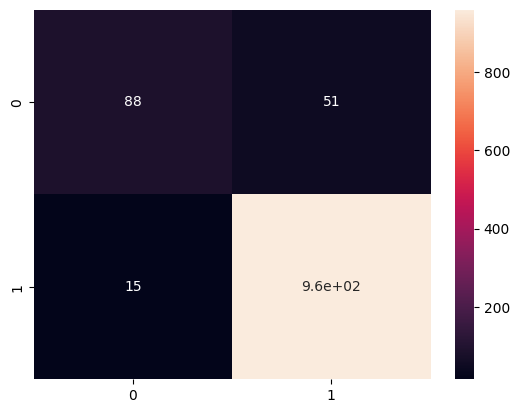

In [ ]:
import seaborn as sbs
sbs.heatmap(cm,annot=True)